# Adel, 2: change a parameter

**What you will learn:** list the model's parameters with their units, change one, compare two simulations, describe
another plant with a few numbers, and incline the tillers.

**You need:** tutorial 1. **Run time:** about 10 seconds.

## 1. The parameters

A **parameter** is a number that describes the plant and stays fixed during a simulation: the number of leaves, the
phyllochron... `parameters()` lists them all with their value, unit, description and the component that uses it.
`parameters(main_only=True)` keeps the main ones.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from openalea.adel.simulation import parameters, simulate

parameters(main_only=True)

,name,value,unit,description,min_value,max_value,component,main
0,leaf_number,NaN,adim,Without tables: the main stem's number of leav...,None,None,ShootArchitecture,True
1,tiller_number,NaN,adim,Without tables: a generated plant's number of ...,None,None,ShootArchitecture,True
2,longest_blade_length,NaN,m,Without tables: a generated plant's longest bl...,None,None,ShootArchitecture,True
3,longest_blade_width,NaN,m,Without tables: a generated plant's longest bl...,None,None,ShootArchitecture,True
4,phyllochron,88.92,°Cd,The phyllochron of every axis,None,None,ScenarioDevelopment,True
5,blade_duration,1.6,phyllochron,"The blade's growth, from its phytomer's appear...",None,None,ScenarioDevelopment,True
6,sheath_duration,1.0,phyllochron,The sheath's growth,None,None,ScenarioDevelopment,True
7,internode_start,2.0,phyllochron,"The internode's growth start, after its phytom...",None,None,ScenarioDevelopment,True
8,internode_duration,1.5,phyllochron,The internode's growth,None,None,ScenarioDevelopment,True
9,senescence_start,5.0,phyllochron,"The blade's senescence start, after its phytom...",None,None,ScenarioDevelopment,True


The same parameters in plain words:

| parameter | what it controls | default |
|---|---|---|
| `leaf_number` | number of leaves of the main stem | (12) |
| `tiller_number` | number of tillers | (4) |
| `longest_blade_length` | length of the longest blade | (19 cm) |
| `longest_blade_width` | width of the longest blade | (1.6 cm) |
| `phyllochron` | thermal time between two successive leaves | 88.92 °Cd |
| `blade_duration` | time a blade takes to grow, in phyllochrons | 1.6 |
| `sheath_duration` | time a sheath takes to grow, in phyllochrons | 1 |
| `internode_start`, `internode_duration` | when an internode starts to grow and for how long, in phyllochrons | 2, 1.5 |
| `senescence_start` | when a blade starts to senesce, in phyllochrons after its appearance | 5 |
| `senescence_duration` | how long its senescence takes, in phyllochrons | 3 |
| `tiller_inclination` | 0: the tillers grow vertical; 1: they lean, as in the field | 0 |

The first four describe **another plant** than the default. Their default value is "not given" (NaN): the plant is then
Adel's sample plant, with measured dimensions. Given any of them, the plant is generated from the four, the missing ones
taking the values in brackets.

The durations count in phyllochrons: with a phyllochron of 89 °Cd, a blade grows for 1.6 × 89 = 142 °Cd.

## 2. Change one parameter

`simulate` takes the parameters to change as a dictionary, `{name: value}`. All the others keep their defaults.
Here the leaves appear every 110 °Cd instead of 88.92:

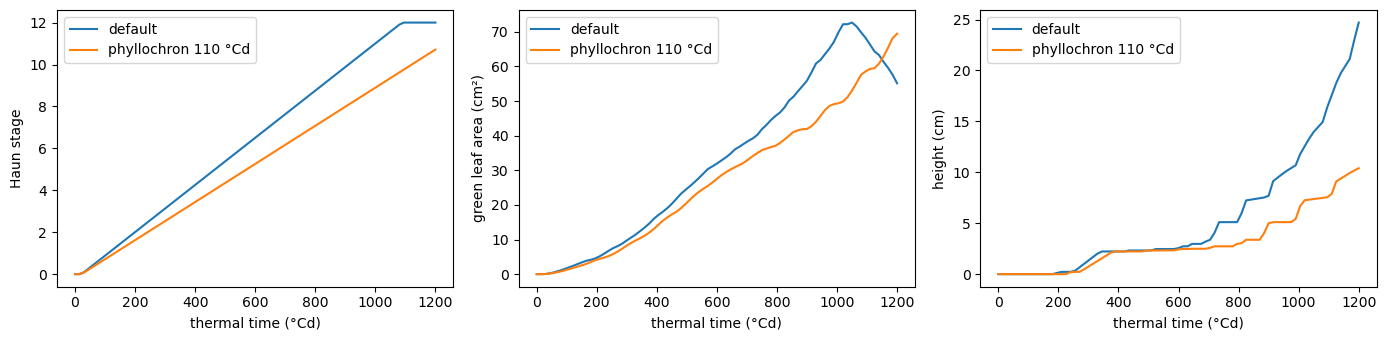

In [2]:
default = simulate(days=80)
slower = simulate({"phyllochron": 110.}, days=80)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for label, result in (("default", default), ("phyllochron 110 °Cd", slower)):
    summary = result.summary
    axes[0].plot(summary["thermal_time"], summary["haun_stage"], label=label)
    axes[1].plot(summary["thermal_time"], summary["green_leaf_area"] * 1e4, label=label)
    axes[2].plot(summary["thermal_time"], summary["height"] * 100, label=label)
axes[0].set_ylabel("Haun stage"); axes[1].set_ylabel("green leaf area (cm²)"); axes[2].set_ylabel("height (cm)")
for ax in axes:
    ax.set_xlabel("thermal time (°Cd)"); ax.legend()
plt.tight_layout()

The leaves appear more slowly: at 1200 °Cd the main stem has not reached its 12th leaf, and the stem, which elongates
later, is much shorter. The green leaf area is larger, though: the senescence also counts in phyllochrons, so fewer
leaves have senesced. A parameter can act on several outputs in opposite directions.

In [3]:
pd.DataFrame({"default": default.summary.iloc[-1], "phyllochron 110 °Cd": slower.summary.iloc[-1]})

,default,phyllochron 110 °Cd
day,80.000000,80.000000
thermal_time,1200.000000,1200.000000
haun_stage,12.000000,10.713245
visible_leaves,12.000000,11.000000
tillers,4.000000,4.000000
height,0.247053,0.104012
green_leaf_area,0.005514,0.006947
senesced_leaf_area,0.005261,0.002943


## 3. Describe another plant

Four numbers describe a plant without tables: its numbers of leaves and tillers, its longest blade's length and
width. Here, a smaller plant with 9 leaves and short blades, next to a generated plant with the default four numbers:

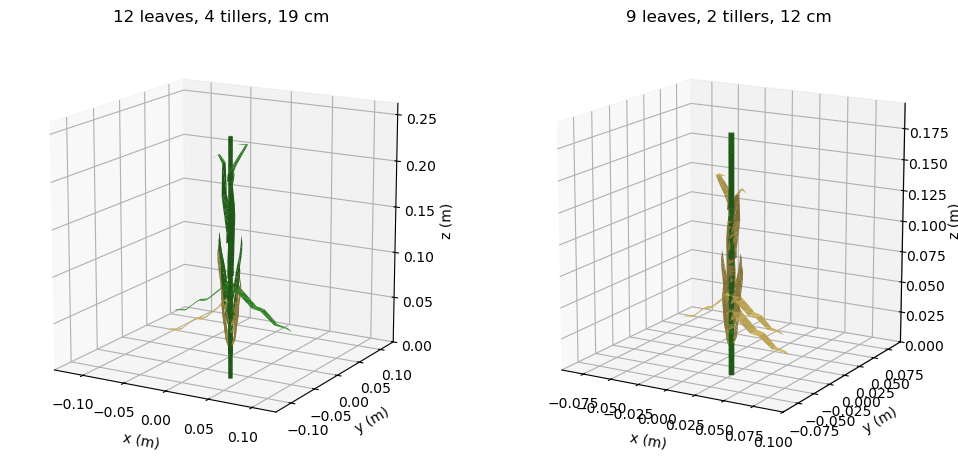

In [4]:
generated = simulate({"leaf_number": 12}, days=80)
small = simulate({"leaf_number": 9, "longest_blade_length": 0.12, "tiller_number": 2}, days=80)

fig = plt.figure(figsize=(12, 6))
for k, (title, result) in enumerate((("12 leaves, 4 tillers, 19 cm", generated),
                                     ("9 leaves, 2 tillers, 12 cm", small))):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    result.draw(ax)
    ax.set_title(title)

The generated plant with the default numbers is close to Adel's sample plant, but not identical: its dimensions
follow Adel's reference profiles along the stem, scaled to its longest blade.

## 4. Inclined tillers

By default the tillers grow vertical, as in Adel's dynamic version. With `tiller_inclination` 1, they lean out from the
main stem and straighten later, as in the field:

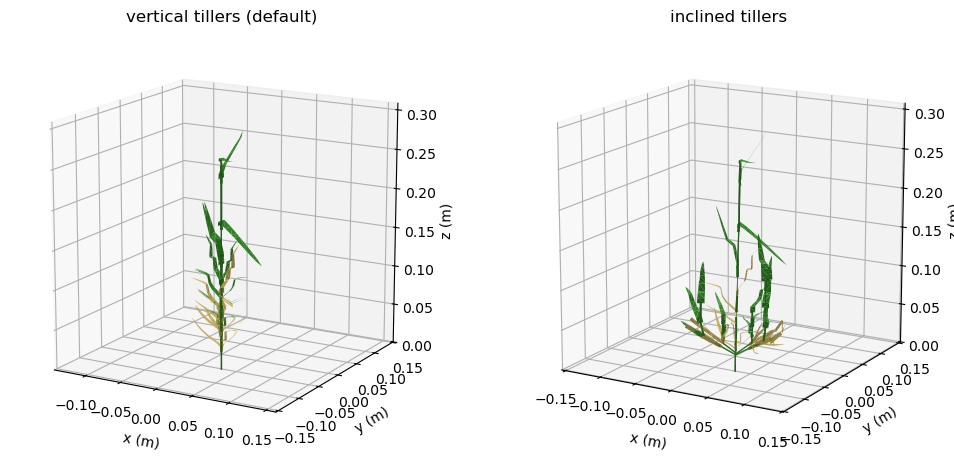

In [5]:
inclined = simulate({"tiller_inclination": 1}, days=80)
fig = plt.figure(figsize=(12, 6))
for k, (title, result) in enumerate((("vertical tillers (default)", default), ("inclined tillers", inclined))):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    result.draw(ax)
    ax.set_title(title)

## 5. A model without chance

This model has no random part: the same parameters always give the same plant. In a stand of several plants
(`simulate(..., plants=10)`), each plant's position, rotation and delay are drawn at random from a **seed**
(`seed=0` by default), as plants in a field differ.

## Try it yourself

1. Set `senescence_start` to 4 instead of 5. When does the green leaf area start to fall?
2. Describe a plant with 14 leaves (`leaf_number`). How tall is it after 80 days, compared with 12 leaves?
3. Grow a stand of 6 plants (`plants=6`) and draw it.

**Next:** `03_combine_parameters.ipynb`.